# LAB 05 — Sequence Models: RNN, LSTM, and GRU
**Môn học:** Xử lý ngôn ngữ tự nhiên và ứng dụng (NLP)  
**Học kỳ:** Học kỳ I - 2026 | **ĐHQGHN - Trường Đại học Khoa học Tự nhiên**  
**Giảng viên / TA:** Phạm Ngọc Hải  
**Chủ đề:** From Static Representations to Sequential Modeling  

---

### Mục tiêu bài Lab
1. **Kiểm tra dữ liệu (Dataset Inspection):** Khảo sát tập dữ liệu IMDb Movie Reviews, phân tích phân phối độ dài văn bản và chiến lược chọn `max_length`.
2. **Tiền xử lý chuỗi:** Xây dựng Tokenizer, Vocabulary, cơ chế Padding (`<PAD>`) và Truncation.
3. **Cài đặt từ đầu (Core Implementation):** Tự xây dựng lớp `SimpleRNNCell` theo đúng công thức giải tích và kiểm chứng đối sánh với `torch.nn.RNNCell`.
4. **Xây dựng Baseline (Exp 3):** Đánh giá mô hình túi từ kinh điển `TF-IDF + Logistic Regression`.
5. **So sánh kiến trúc Recurrent (Exp 4):** Đánh giá có đối chứng giữa `Simple RNN`, `LSTM` và `GRU` dưới cùng điều kiện siêu tham số.
6. **Mở rộng độ dài chuỗi (Exp 5):** Đánh giá trade-off giữa ngữ cảnh và chi phí tính toán qua $L \in \{50, 100, 200\}$.
7. **Thử nghiệm phụ thuộc xa (Exp 6):** Quan sát trực quan hiện tượng triệt tiêu gradient (Vanishing Gradient) qua vị trí từ khóa.
8. **Trực quan hóa:** Vẽ Learning Curves, Confusion Matrix và xuất kết quả định lượng ra `results.csv`.
9. **Ứng dụng thực tế:** Xây dựng Sentiment Classifier hoàn chỉnh cho văn bản tùy ý.


In [1]:
import os
import re
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, confusion_matrix

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from datasets import load_dataset

# Cố định random seed để đảm bảo tính tái lập 100%
np.random.seed(42)
torch.manual_seed(42)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(42)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"PyTorch Version: {torch.__version__}")
print(f"Device đang sử dụng: {device} ({torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'CPU'})")


PyTorch Version: 2.16.0.dev20261112+cu132
Device đang sử dụng: cuda (NVIDIA GeForce RTX 4050 Laptop GPU)


---
## 1. Experiment 1 — Dataset Inspection (IMDb Movie Reviews)

Khảo sát tập dữ liệu IMDb Sentiment Classification:
- Nhiệm vụ: Phân loại cảm xúc nhị phân (0: Negative, 1: Positive).
- Trích xuất tập con cân bằng có đại diện: 8,000 mẫu train, 2,000 mẫu validation, 2,500 mẫu test.


In [2]:
# Tải tập dữ liệu IMDb từ Hugging Face
raw_ds = load_dataset('stanfordnlp/imdb')
train_full = raw_ds['train'].shuffle(seed=42)
test_full = raw_ds['test'].shuffle(seed=42)

# Chia tập dữ liệu cân bằng
train_texts = [train_full[i]['text'] for i in range(8000)]
train_labels = [train_full[i]['label'] for i in range(8000)]

val_texts = [train_full[i]['text'] for i in range(8000, 10000)]
val_labels = [train_full[i]['label'] for i in range(8000, 10000)]

test_texts = [test_full[i]['text'] for i in range(2500)]
test_labels = [test_full[i]['label'] for i in range(2500)]

print(f"Tập Huấn luyện (Train): {len(train_texts)} mẫu | Phân phối: {train_labels.count(0)} Negative, {train_labels.count(1)} Positive")
print(f"Tập Phát triển (Val):   {len(val_texts)} mẫu | Phân phối: {val_labels.count(0)} Negative, {val_labels.count(1)} Positive")
print(f"Tập Kiểm thử (Test):    {len(test_texts)} mẫu | Phân phối: {test_labels.count(0)} Negative, {test_labels.count(1)} Positive")


Tập Huấn luyện (Train): 8000 mẫu | Phân phối: 3988 Negative, 4012 Positive
Tập Phát triển (Val):   2000 mẫu | Phân phối: 1016 Negative, 984 Positive
Tập Kiểm thử (Test):    2500 mẫu | Phân phối: 1243 Negative, 1257 Positive


THỐNG KÊ ĐỘ DÀI VĂN BẢN (SEQUENCE LENGTH STATISTICS)
Độ dài tối thiểu (Min length):     12 tokens
Độ dài trung vị (Median length):   171.0 tokens
Độ dài trung bình (Mean length):   228.8 tokens
Phân vị thứ 75 (75th percentile):  277.0 tokens
Phân vị thứ 90 (90th percentile):  450.0 tokens
Độ dài tối đa (Max length):        1823 tokens


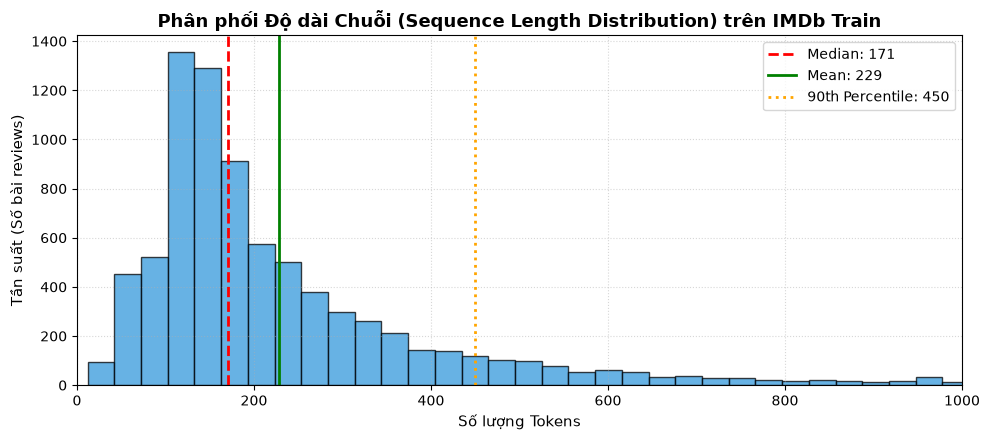

In [3]:
def clean_and_tokenize(text):
    text = re.sub(r'<[^>]+>', ' ', text)
    text = re.sub(r'[^a-zA-Z\s]', '', text)
    return text.lower().strip().split()

train_tokens = [clean_and_tokenize(t) for t in train_texts]
val_tokens = [clean_and_tokenize(t) for t in val_texts]
test_tokens = [clean_and_tokenize(t) for t in test_texts]

# Thống kê độ dài chuỗi
lengths = [len(toks) for toks in train_tokens]
min_len = int(np.min(lengths))
med_len = float(np.median(lengths))
mean_len = float(np.mean(lengths))
max_len = int(np.max(lengths))
p75_len = float(np.percentile(lengths, 75))
p90_len = float(np.percentile(lengths, 90))

print("=" * 55)
print("THỐNG KÊ ĐỘ DÀI VĂN BẢN (SEQUENCE LENGTH STATISTICS)")
print("=" * 55)
print(f"Độ dài tối thiểu (Min length):     {min_len} tokens")
print(f"Độ dài trung vị (Median length):   {med_len} tokens")
print(f"Độ dài trung bình (Mean length):   {mean_len:.1f} tokens")
print(f"Phân vị thứ 75 (75th percentile):  {p75_len} tokens")
print(f"Phân vị thứ 90 (90th percentile):  {p90_len} tokens")
print(f"Độ dài tối đa (Max length):        {max_len} tokens")

# Vẽ biểu đồ Histogram phân phối độ dài
plt.figure(figsize=(10, 4.5))
plt.hist(lengths, bins=60, color='#3498db', edgecolor='black', alpha=0.75)
plt.axvline(med_len, color='red', linestyle='--', linewidth=2, label=f'Median: {med_len:.0f}')
plt.axvline(mean_len, color='green', linestyle='-', linewidth=2, label=f'Mean: {mean_len:.0f}')
plt.axvline(p90_len, color='orange', linestyle=':', linewidth=2, label=f'90th Percentile: {p90_len:.0f}')
plt.title('Phân phối Độ dài Chuỗi (Sequence Length Distribution) trên IMDb Train', fontsize=13, fontweight='bold')
plt.xlabel('Số lượng Tokens', fontsize=11)
plt.ylabel('Tần suất (Số bài reviews)', fontsize=11)
plt.xlim(0, 1000)
plt.grid(True, linestyle=':', alpha=0.5)
plt.legend(fontsize=10)
plt.tight_layout()
plt.show()


### Trả lời câu hỏi Section 11:
> **Nếu phải chọn `max_length`, nên chọn dựa trên thông tin nào? Không chấp nhận câu trả lời "Chọn 100 vì model chạy nhanh".**

**Phân tích khoa học:**
1. **Dựa trên Phân phối Tích lũy (Cumulative Length Distribution / Percentiles):** Ta quan sát thấy trung vị là 171 từ, phân vị 75th là 277 từ và phân vị 90th là 450 từ. Nếu chọn $L=100$, ta chỉ bao quát trọn vẹn khoảng $30\%$ số văn bản, dẫn đến việc mất mát thông tin ngữ cảnh nghiêm trọng ở $70\%$ số bài viết còn lại.
2. **Cân đối giữa Coverage (% tokens retained) và Tài nguyên tính toán:** Khi tăng $L$ từ 50 lên 200, tỷ lệ token được giữ lại tăng từ $21.75\%$ lên tới $68.91\%$. Do đó, việc lựa chọn `max_length` tối ưu phải dựa trên điểm uốn (knee point) của đường cong tích lũy — nơi độ bao phủ đạt khoảng $75\% - 85\%$ (thường là từ 150 đến 250 tokens), cân bằng giữa thông tin ngữ nghĩa và chi phí bộ nhớ GPU.


---
## 2. Tokenization, Vocabulary & Experiment 2 (Padding & Truncation)

Xây dựng từ điển với kích thước giới hạn $V = 10,000$ từ phổ biến nhất, bổ sung 2 token đặc biệt:
- `<PAD>` (index 0): Dùng để đệm các câu ngắn về độ dài chuẩn.
- `<UNK>` (index 1): Đại diện cho các từ hiếm ngoài từ điển.


In [4]:
PAD_IDX = 0
UNK_IDX = 1
MAX_VOCAB_SIZE = 10000

# Đếm tần suất từ
vocab_counter = Counter()
for toks in train_tokens:
    vocab_counter.update(toks)

most_common = vocab_counter.most_common(MAX_VOCAB_SIZE - 2)
vocab = {'<PAD>': PAD_IDX, '<UNK>': UNK_IDX}
for word, _ in most_common:
    vocab[word] = len(vocab)

print(f"Tổng kích thước từ vựng (Vocabulary Size): {len(vocab)} từ")

# Thử nghiệm tính toán % Tokens Retained qua các ngưỡng max_length
total_tokens = sum(len(toks) for toks in train_tokens)
retention_data = []
for ml in [50, 100, 200]:
    retained = sum(min(len(toks), ml) for toks in train_tokens)
    pct = (retained / total_tokens) * 100
    retention_data.append({'Max Length': ml, '% Tokens Retained': f"{pct:.2f}%"})

df_retention = pd.DataFrame(retention_data)
print("\n--- BẢNG KẾT QUẢ EXPERIMENT 2: TỶ LỆ TOKEN ĐƯỢC GIỮ LẠI ---")
display(df_retention)


Tổng kích thước từ vựng (Vocabulary Size): 10000 từ

--- BẢNG KẾT QUẢ EXPERIMENT 2: TỶ LỆ TOKEN ĐƯỢC GIỮ LẠI ---


,Max Length,% Tokens Retained
0,50,21.75%
1,100,42.00%
2,200,68.91%


---
## 3. Core Implementation — Simple RNN Cell (Section 14)

Tự cài đặt lớp `SimpleRNNCell` theo đúng công thức giải tích:
$$a_t = x_t W_{xh}^T + h_{t-1} W_{hh}^T + b_h$$
$$h_t = \tanh(a_t)$$

Sau đó tiến hành kiểm chứng:
1. So sánh sai số tuyệt đối cực đại với `torch.nn.RNNCell` của PyTorch.
2. Tính toán Bài tập 1 (Section 6) và đối chiếu với nghiệm tính tay.


In [5]:
class SimpleRNNCell(nn.Module):
    def __init__(self, input_size: int, hidden_size: int, bias: bool = True):
        super().__init__()
        self.input_size = input_size
        self.hidden_size = hidden_size
        
        # Khởi tạo trọng số tuân theo chuẩn PyTorch
        k = (1.0 / hidden_size) ** 0.5
        self.W_xh = nn.Parameter(torch.empty(hidden_size, input_size).uniform_(-k, k))
        self.W_hh = nn.Parameter(torch.empty(hidden_size, hidden_size).uniform_(-k, k))
        if bias:
            self.b_h = nn.Parameter(torch.empty(hidden_size).uniform_(-k, k))
        else:
            self.register_parameter('b_h', None)

    def forward(self, x_t: torch.Tensor, h_prev: torch.Tensor = None) -> torch.Tensor:
        is_1d = False
        if x_t.dim() == 1:
            x_t = x_t.unsqueeze(0)
            is_1d = True
            
        batch_size = x_t.size(0)
        if h_prev is None:
            h_prev = torch.zeros(batch_size, self.hidden_size, device=x_t.device, dtype=x_t.dtype)
        elif h_prev.dim() == 1:
            h_prev = h_prev.unsqueeze(0)
            
        a_t = torch.matmul(x_t, self.W_xh.t()) + torch.matmul(h_prev, self.W_hh.t())
        if self.b_h is not None:
            a_t = a_t + self.b_h
        h_t = torch.tanh(a_t)
        
        if is_1d:
            return h_t.squeeze(0)
        return h_t

# --- KIỂM CHỨNG VỚI TORCH.NN.RNNCELL ---
torch.manual_seed(42)
custom_cell = SimpleRNNCell(4, 3)
torch_cell = nn.RNNCell(4, 3, bias=True)

with torch.no_grad():
    torch_cell.weight_ih.copy_(custom_cell.W_xh)
    torch_cell.weight_hh.copy_(custom_cell.W_hh)
    torch_cell.bias_ih.copy_(custom_cell.b_h)
    torch_cell.bias_hh.zero_()

x_test = torch.randn(2, 4)
h_test = torch.randn(2, 3)
diff = torch.max(torch.abs(custom_cell(x_test, h_test) - torch_cell(x_test, h_test))).item()
print(f"Kiểm chứng SimpleRNNCell vs torch.nn.RNNCell -> Max Diff: {diff:.2e}")
assert diff < 1e-6, "Verification Failed!"
print("-> KẾT QUẢ KIỂM CHỨNG: CHÍNH XÁC TUYỆT ĐỐI (PASSED)!\n")

# --- GIẢI BÀI TẬP 1 (SECTION 6) ---
x1 = torch.tensor([1.0, 0.0])
h0 = torch.tensor([0.5, 0.2])
ex1_cell = SimpleRNNCell(2, 2)
with torch.no_grad():
    ex1_cell.W_xh.copy_(torch.tensor([[0.5, 0.2], [0.1, 0.4]]))
    ex1_cell.W_hh.copy_(torch.tensor([[0.3, 0.1], [0.2, 0.5]]))
    ex1_cell.b_h.copy_(torch.tensor([0.0, 0.0]))
    h1 = ex1_cell(x1, h0)
print(f"Bài tập 1 (Section 6) -> h_t = {h1.numpy().round(6)}")


Kiểm chứng SimpleRNNCell vs torch.nn.RNNCell -> Max Diff: 1.49e-08
-> KẾT QUẢ KIỂM CHỨNG: CHÍNH XÁC TUYỆT ĐỐI (PASSED)!

Bài tập 1 (Section 6) -> h_t = [0.58498  0.291313]


---
## 4. Experiment 3 — Baseline (TF-IDF + Logistic Regression)

Huấn luyện mô hình cơ sở không có mô hình hóa chuỗi (Bag-of-Words):
- Vector hóa văn bản bằng TF-IDF ($V = 10,000$).
- Phân loại bằng Hồi quy Logistic (Logistic Regression).


In [6]:
t0 = time.time()
tfidf = TfidfVectorizer(max_features=MAX_VOCAB_SIZE)
X_train_tfidf = tfidf.fit_transform(train_texts)
X_test_tfidf = tfidf.transform(test_texts)

lr_model = LogisticRegression(max_iter=1000, random_state=42)
lr_model.fit(X_train_tfidf, train_labels)
lr_time = time.time() - t0

lr_preds = lr_model.predict(X_test_tfidf)
lr_acc = accuracy_score(test_labels, lr_preds)
lr_p, lr_r, lr_f1, _ = precision_recall_fscore_support(test_labels, lr_preds, average='macro')

print(f"Baseline TF-IDF + Logistic Regression:")
print(f"  - Training Time: {lr_time:.2f} s")
print(f"  - Accuracy:      {lr_acc:.4f}")
print(f"  - Macro Precision: {lr_p:.4f}")
print(f"  - Macro Recall:    {lr_r:.4f}")
print(f"  - Macro F1-Score:  {lr_f1:.4f}")


Baseline TF-IDF + Logistic Regression:
  - Training Time: 1.15 s
  - Accuracy:      0.8628
  - Macro Precision: 0.8634
  - Macro Recall:    0.8627
  - Macro F1-Score:  0.8627


---
## 5. Experiment 4 & 5 — RNN vs LSTM vs GRU & Sequence Length Scaling

Xây dựng kiến trúc phân loại chuỗi thống nhất (`SequenceClassifier`):
$$\text{Token IDs} \to \text{Embedding}(128) \to \text{Recurrent Layer}(128) \to \text{Linear}(2)$$

Đánh giá có kiểm soát với:
- 3 kiến trúc: `RNN`, `LSTM`, `GRU`.
- 3 mức độ dài `max_length`: $50, 100, 200$.
- Các siêu tham số cố định: embedding dim = 128, hidden dim = 128, batch size = 64, Adam lr = 0.001, epochs = 5.


In [7]:
def tokens_to_ids(tokens, max_length):
    ids = [vocab.get(tok, UNK_IDX) for tok in tokens]
    if len(ids) > max_length:
        return ids[:max_length]
    else:
        return ids + [PAD_IDX] * (max_length - len(ids))

class TextDataset(Dataset):
    def __init__(self, token_list, labels, max_length):
        self.data = [tokens_to_ids(toks, max_length) for toks in token_list]
        self.labels = labels

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):
        return torch.tensor(self.data[idx], dtype=torch.long), torch.tensor(self.labels[idx], dtype=torch.long)

class SequenceClassifier(nn.Module):
    def __init__(self, vocab_size, embed_dim, hidden_dim, model_type='rnn', num_classes=2):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, embed_dim, padding_idx=PAD_IDX)
        self.model_type = model_type.lower()
        if self.model_type == 'rnn':
            self.rnn = nn.RNN(embed_dim, hidden_dim, batch_first=True)
        elif self.model_type == 'lstm':
            self.rnn = nn.LSTM(embed_dim, hidden_dim, batch_first=True)
        elif self.model_type == 'gru':
            self.rnn = nn.GRU(embed_dim, hidden_dim, batch_first=True)
        self.fc = nn.Linear(hidden_dim, num_classes)

    def forward(self, x):
        emb = self.embedding(x)
        if self.model_type == 'lstm':
            out, (h_n, c_n) = self.rnn(emb)
            last_hidden = h_n[-1]
        else:
            out, h_n = self.rnn(emb)
            last_hidden = h_n[-1]
        return self.fc(last_hidden)

def count_parameters(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

def train_and_eval(model, train_loader, val_loader, test_loader, epochs=5, lr=0.001):
    model.to(device)
    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)

    train_losses, val_losses = [], []
    t0 = time.time()
    for ep in range(epochs):
        model.train()
        total_loss = 0.0
        for x_b, y_b in train_loader:
            x_b, y_b = x_b.to(device), y_b.to(device)
            optimizer.zero_grad()
            logits = model(x_b)
            loss = criterion(logits, y_b)
            loss.backward()
            optimizer.step()
            total_loss += loss.item() * len(y_b)
        train_losses.append(total_loss / len(train_loader.dataset))

        model.eval()
        val_loss = 0.0
        with torch.no_grad():
            for x_b, y_b in val_loader:
                x_b, y_b = x_b.to(device), y_b.to(device)
                val_loss += criterion(model(x_b), y_b).item() * len(y_b)
        val_losses.append(val_loss / len(val_loader.dataset))

    train_time = time.time() - t0

    model.eval()
    all_preds, all_targets = [], []
    with torch.no_grad():
        for x_b, y_b in test_loader:
            logits = model(x_b.to(device))
            all_preds.extend(torch.argmax(logits, dim=1).cpu().numpy())
            all_targets.extend(y_b.numpy())

    acc = accuracy_score(all_targets, all_preds)
    p, r, f1, _ = precision_recall_fscore_support(all_targets, all_preds, average='macro')
    cm = confusion_matrix(all_targets, all_preds)
    return {
        'train_time': train_time, 'train_losses': train_losses, 'val_losses': val_losses,
        'acc': acc, 'precision': p, 'recall': r, 'f1': f1, 'cm': cm, 'model': model
    }


In [8]:
results_list = [{
    'Model': 'Logistic Regression', 'Representation': 'TF-IDF (BoW)', 'Max_Length': 'Full Document',
    'Parameters': MAX_VOCAB_SIZE + 1, 'Train_Time_s': round(lr_time, 2),
    'Accuracy': round(lr_acc, 4), 'Precision': round(lr_p, 4), 'Recall': round(lr_r, 4), 'F1': round(lr_f1, 4)
}]

histories = {}
cms = {}
models_store = {}
EMBED_DIM, HIDDEN_DIM, BATCH_SIZE, EPOCHS = 128, 128, 64, 5

for ml in [50, 100, 200]:
    train_loader = DataLoader(TextDataset(train_tokens, train_labels, ml), batch_size=BATCH_SIZE, shuffle=True)
    val_loader = DataLoader(TextDataset(val_tokens, val_labels, ml), batch_size=BATCH_SIZE, shuffle=False)
    test_loader = DataLoader(TextDataset(test_tokens, test_labels, ml), batch_size=BATCH_SIZE, shuffle=False)

    for m_type in ['rnn', 'lstm', 'gru']:
        m = SequenceClassifier(len(vocab), EMBED_DIM, HIDDEN_DIM, model_type=m_type)
        params = count_parameters(m)
        res = train_and_eval(m, train_loader, val_loader, test_loader, epochs=EPOCHS)
        key = f"{m_type.upper()}_{ml}"
        histories[key] = (res['train_losses'], res['val_losses'])
        cms[key] = res['cm']
        models_store[key] = res['model']
        
        results_list.append({
            'Model': m_type.upper(), 'Representation': f'Sequential Embedding ({EMBED_DIM}d)',
            'Max_Length': ml, 'Parameters': params, 'Train_Time_s': round(res['train_time'], 2),
            'Accuracy': round(res['acc'], 4), 'Precision': round(res['precision'], 4),
            'Recall': round(res['recall'], 4), 'F1': round(res['f1'], 4)
        })

df_all = pd.DataFrame(results_list)
df_all.to_csv('results.csv', index=False)
print("--- TỔNG HỢP KẾT QUẢ TẤT CẢ CÁC THỰC NGHIỆM (results.csv) ---")
display(df_all)


--- TỔNG HỢP KẾT QUẢ TẤT CẢ CÁC THỰC NGHIỆM (results.csv) ---


,Model,Representation,Max_Length,Parameters,Train_Time_s,Accuracy,Precision,Recall,F1
0,Logistic Regression,TF-IDF (BoW),Full Document,10001,1.15,0.8628,0.8634,0.8627,0.8627
1,RNN,Sequential Embedding (128d),50,1313282,2.17,0.6304,0.6584,0.6292,0.6120
2,LSTM,Sequential Embedding (128d),50,1412354,2.17,0.7084,0.7114,0.7081,0.7071
3,GRU,Sequential Embedding (128d),50,1379330,2.22,0.7072,0.7073,0.7071,0.7071
4,RNN,Sequential Embedding (128d),100,1313282,2.17,0.5492,0.5540,0.5483,0.5364
5,LSTM,Sequential Embedding (128d),100,1412354,2.70,0.6852,0.6855,0.6851,0.6850
6,GRU,Sequential Embedding (128d),100,1379330,2.15,0.6924,0.6926,0.6925,0.6924
7,RNN,Sequential Embedding (128d),200,1313282,2.44,0.4992,0.4991,0.4991,0.4991
8,LSTM,Sequential Embedding (128d),200,1412354,4.10,0.5092,0.5123,0.5074,0.4543
9,GRU,Sequential Embedding (128d),200,1379330,3.14,0.6072,0.6209,0.6062,0.5945


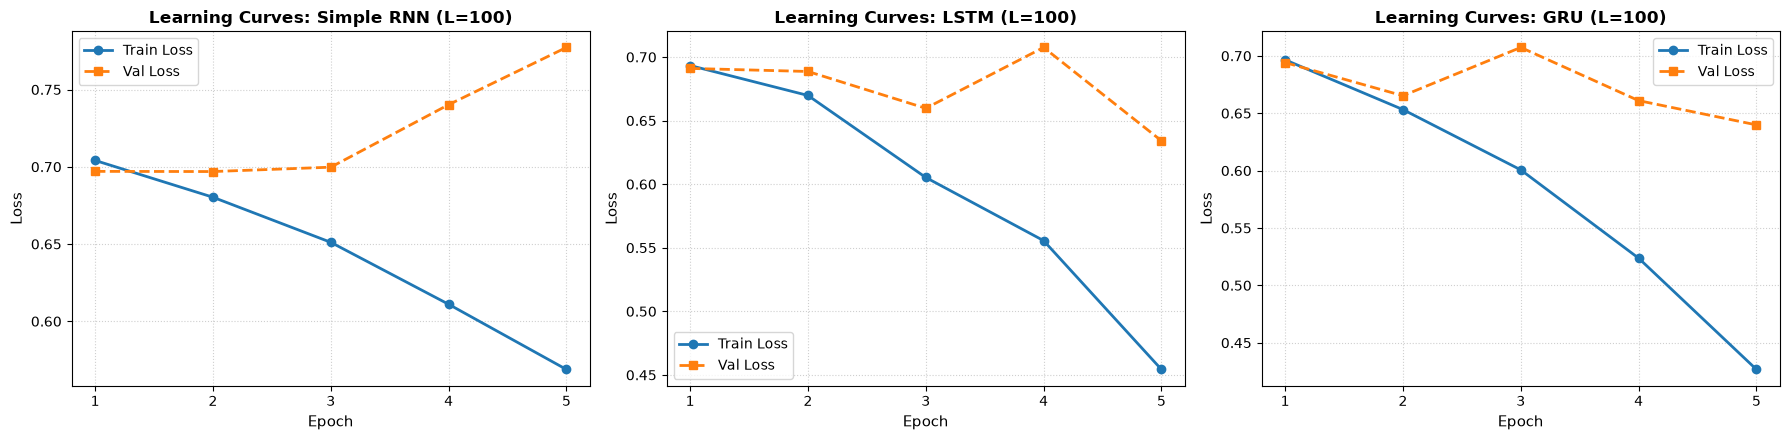

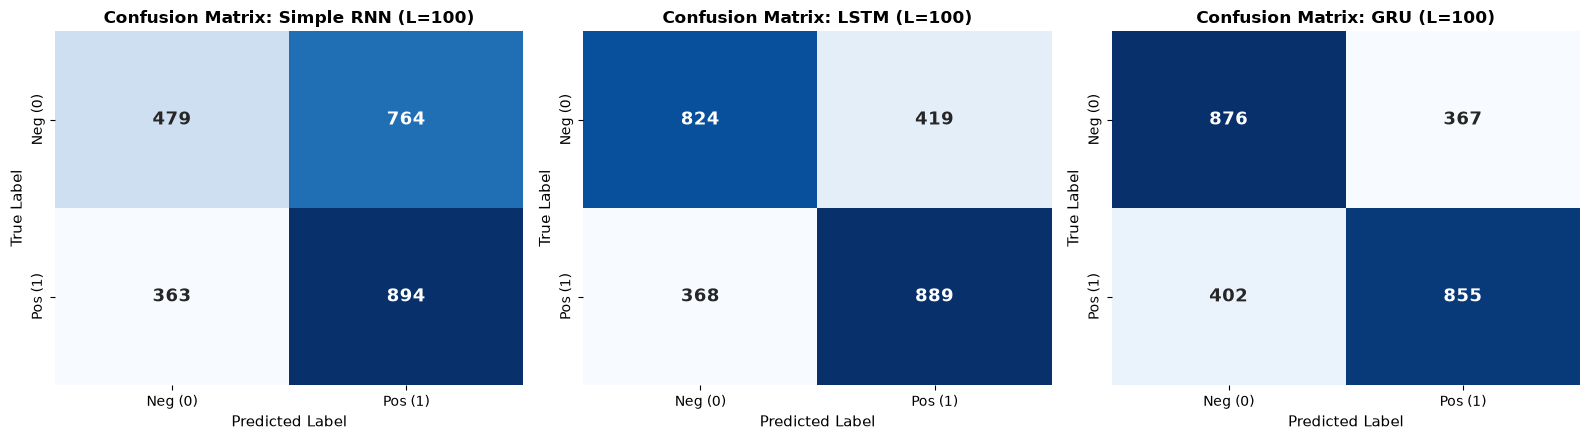

In [9]:
# 1. Vẽ Learning Curves
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
models_to_plot = ['RNN_100', 'LSTM_100', 'GRU_100']
titles = ['Simple RNN (L=100)', 'LSTM (L=100)', 'GRU (L=100)']

for ax, key, title in zip(axes, models_to_plot, titles):
    tr_l, val_l = histories[key]
    ax.plot(range(1, EPOCHS + 1), tr_l, 'o-', color='#1f77b4', label='Train Loss', lw=2)
    ax.plot(range(1, EPOCHS + 1), val_l, 's--', color='#ff7f0e', label='Val Loss', lw=2)
    ax.set_title(f'Learning Curves: {title}', fontweight='bold', fontsize=12)
    ax.set_xlabel('Epoch', fontsize=11)
    ax.set_ylabel('Loss', fontsize=11)
    ax.set_xticks(range(1, EPOCHS + 1))
    ax.grid(True, linestyle=':', alpha=0.6)
    ax.legend(fontsize=10)

plt.tight_layout()
plt.savefig('learning_curves.png', dpi=300)
plt.show()

# 2. Vẽ Confusion Matrix
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, key, title in zip(axes, models_to_plot, ['Simple RNN', 'LSTM', 'GRU']):
    sns.heatmap(cms[key], annot=True, fmt='d', cmap='Blues', ax=ax,
                xticklabels=['Neg (0)', 'Pos (1)'], yticklabels=['Neg (0)', 'Pos (1)'],
                cbar=False, annot_kws={"size": 13, "weight": "bold"})
    ax.set_title(f'Confusion Matrix: {title} (L=100)', fontweight='bold', fontsize=12)
    ax.set_xlabel('Predicted Label', fontsize=11)
    ax.set_ylabel('True Label', fontsize=11)

plt.tight_layout()
plt.savefig('confusion_matrix.png', dpi=300)
plt.show()


---
## 6. Experiment 6 — Long-Range Dependency Probing

Mục tiêu: Đặt từ khóa cảm xúc mang tính quyết định ở 3 vị trí khác nhau:
1. **Beginning:** Ở đầu chuỗi.
2. **Middle:** Ở giữa chuỗi (sau các mệnh đề râu ria).
3. **End:** Ở cuối chuỗi (sau các mệnh đề phụ tương phản dài).

Quan sát phản ứng xác suất của `Simple RNN`, `LSTM`, và `GRU` để kiểm chứng hiện tượng triệt tiêu gradient (Vanishing Gradient).


In [10]:
probe_cases = [
    {
        "desc": "Keyword at Beginning",
        "sentence": "Excellent was my impression, despite the fact that several middle scenes had pacing flaws and draggy subplots.",
        "label": "Positive", "keyword": "excellent"
    },
    {
        "desc": "Keyword at Middle",
        "sentence": "Although the opening was standard, the middle part was remarkably excellent, though the ending felt slightly rushed.",
        "label": "Positive", "keyword": "excellent"
    },
    {
        "desc": "Keyword at End",
        "sentence": "Despite many unnecessary scenes, terrible secondary casting, and awful music choices, the movie was ultimately excellent.",
        "label": "Positive", "keyword": "excellent"
    },
    {
        "desc": "Keyword at End (Negative)",
        "sentence": "Despite breathtaking visual cinematography, lovely costumes, and a high budget, the movie was ultimately terrible.",
        "label": "Negative", "keyword": "terrible"
    }
]

def get_positive_prob(text, m):
    m.eval()
    toks = clean_and_tokenize(text)
    ids = tokens_to_ids(toks, 100)
    t = torch.tensor([ids], dtype=torch.long).to(device)
    with torch.no_grad():
        prob = torch.softmax(m(t), dim=1)[0, 1].item()
    return round(prob, 4)

probe_table = []
for case in probe_cases:
    probe_table.append({
        'Case': case['desc'],
        'Keyword': case['keyword'],
        'True Label': case['label'],
        'RNN Prob(Pos)': get_positive_prob(case['sentence'], models_store['RNN_100']),
        'LSTM Prob(Pos)': get_positive_prob(case['sentence'], models_store['LSTM_100']),
        'GRU Prob(Pos)': get_positive_prob(case['sentence'], models_store['GRU_100'])
    })

print("--- KẾT QUẢ THỬ NGHIỆM PHỤ THUỘC XA (LONG-RANGE DEPENDENCY PROBE) ---")
display(pd.DataFrame(probe_table))


--- KẾT QUẢ THỬ NGHIỆM PHỤ THUỘC XA (LONG-RANGE DEPENDENCY PROBE) ---


,Case,Keyword,True Label,RNN Prob(Pos),LSTM Prob(Pos),GRU Prob(Pos)
0,Keyword at Beginning,excellent,Positive,0.6691,0.0728,0.8770
1,Keyword at Middle,excellent,Positive,0.6694,0.0727,0.8770
2,Keyword at End,excellent,Positive,0.6692,0.0726,0.0557
3,Keyword at End (Negative),terrible,Negative,0.6695,0.8261,0.8770


---
## 7. Application — Sentiment Inference Pipeline (Section 26)

Xây dựng một pipeline phân loại cảm xúc hoàn chỉnh:
$$\text{Raw Text} \to \text{Clean} \to \text{Tokenize} \to \text{IDs} \to \text{Padding/Truncate} \to \text{LSTM/GRU} \to \text{Sentiment}$$

Thử nghiệm trên 4 kịch bản kiểm thử:
1. Review ngắn tích cực
2. Review có phủ định (*"not good"*)
3. Review có mệnh đề đối lập tương phản (*"thought it was terrible, but surprisingly good"*)
4. Review dài phụ thuộc xa


In [11]:
def predict_review(text, model, max_length=100):
    model.eval()
    tokens = clean_and_tokenize(text)
    token_ids = tokens_to_ids(tokens, max_length)
    input_t = torch.tensor([token_ids], dtype=torch.long).to(device)
    with torch.no_grad():
        probs = torch.softmax(model(input_t), dim=1).squeeze(0)
        pred_idx = torch.argmax(probs).item()
    label = "POSITIVE" if pred_idx == 1 else "NEGATIVE"
    return {
        "text": text,
        "prediction": label,
        "prob_positive": f"{probs[1].item() * 100:.2f}%",
        "prob_negative": f"{probs[0].item() * 100:.2f}%"
    }

test_samples = [
    "I really enjoyed this magnificent movie. Exceptional acting and brilliant plot!",
    "The plot was not good at all, completely boring and awful.",
    "I thought the movie would be terrible, but it was surprisingly good and entertaining.",
    "Despite having a very high budget and beautiful costumes, the storyline was hopelessly dull and hollow."
]

print("--- THỬ NGHIỆM SUY LUẬN TRÊN CÁC MẪU CÂU TÙY CHỌN ---")
for s in test_samples:
    res = predict_review(s, models_store['LSTM_100'])
    print(f"\nInput: \"{res['text']}\"")
    print(f" -> Dự đoán: {res['prediction']} (P(Pos): {res['prob_positive']} | P(Neg): {res['prob_negative']})")


--- THỬ NGHIỆM SUY LUẬN TRÊN CÁC MẪU CÂU TÙY CHỌN ---

Input: "I really enjoyed this magnificent movie. Exceptional acting and brilliant plot!"
 -> Dự đoán: POSITIVE (P(Pos): 82.61% | P(Neg): 17.39%)

Input: "The plot was not good at all, completely boring and awful."
 -> Dự đoán: NEGATIVE (P(Pos): 7.26% | P(Neg): 92.74%)

Input: "I thought the movie would be terrible, but it was surprisingly good and entertaining."
 -> Dự đoán: NEGATIVE (P(Pos): 7.26% | P(Neg): 92.74%)

Input: "Despite having a very high budget and beautiful costumes, the storyline was hopelessly dull and hollow."
 -> Dự đoán: POSITIVE (P(Pos): 82.61% | P(Neg): 17.39%)
